# Stage 2
**M2 Training Preparation | Thumbnail → Query Generator**

In [1]:
# Install required packages
#!pip uninstall -q -y clip 2>/dev/null || true
!pip install -q ftfy regex tqdm
!pip install -q git+https://github.com/openai/CLIP.git
!pip install -q transformers sacrebleu rouge-score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 6.7 MB/s eta 0:00:00
CLIP installation OK — clip.load is available.


# 0. Mount Drive & Imports

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os, json, random, re, math
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image, ImageStat
from tqdm import tqdm
import matplotlib.gridspec as gridspec

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

import clip
from transformers import GPT2Tokenizer, GPT2LMHeadModel, get_cosine_schedule_with_warmup

import sacrebleu
from rouge_score import rouge_scorer

In [4]:
# Paths
PROJECT_ROOT  = Path("/content/drive/MyDrive/thumbnail_project")
PROCESSED_DIR = PROJECT_ROOT / "processed"
FRAMES_DIR    = PROJECT_ROOT / "qvh_frames"
VIDEO_DIR     = PROJECT_ROOT / "qvh_videos"
CKPT_DIR      = PROJECT_ROOT / "checkpoints"
CKPT_DIR.mkdir(exist_ok=True)

# Output paths for this phase
SPLIT_INDICES_PATH = PROCESSED_DIR / "m2_split_indices.json"
VOCAB_STATS_PATH   = PROCESSED_DIR / "m2_vocab_stats.json"
M2_PAIRS_PATH    = PROCESSED_DIR / "m2_train_pairs.jsonl"
TRAIN_PROC_PATH  = PROCESSED_DIR / "train_processed.jsonl"
DOWNLOAD_LOG     = PROCESSED_DIR / "download_log.json"

print("Project root :", PROJECT_ROOT)
print("Directories  :")
for d in [PROCESSED_DIR, FRAMES_DIR, VIDEO_DIR]:
    exists = "✓" if d.exists() else "✗ MISSING"
    print(f"  {exists}  {d}")

Project root : /content/drive/MyDrive/thumbnail_project
Directories  :
  ✓  /content/drive/MyDrive/thumbnail_project/processed
  ✓  /content/drive/MyDrive/thumbnail_project/qvh_frames
  ✓  /content/drive/MyDrive/thumbnail_project/qvh_videos


In [5]:
# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU    : {torch.cuda.get_device_name(0)}")
    print(f"VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

Device : cuda
GPU    : Tesla T4
VRAM   : 15.6 GB


In [6]:
# Shared helpers
def load_jsonl(path):
    with open(path) as f:
        return [json.loads(l) for l in f if l.strip()]

def save_jsonl(records, path):
    with open(path, "w") as f:
        for r in records:
            f.write(json.dumps(r) + "\n")
    print(f"  Saved {len(records):,} records → {path.name}")

### A1: Data Check

In [7]:
# Load the M2 pairs manifest
m2_pairs = load_jsonl(M2_PAIRS_PATH)
print(f"Records in m2_train_pairs.jsonl : {len(m2_pairs):,}")
print("\nSample record:")
print(json.dumps(m2_pairs[0], indent=2))

Records in m2_train_pairs.jsonl : 1,608

Sample record:
{
  "qid": 1,
  "frame_path": "/content/drive/MyDrive/thumbnail_project/qvh_frames/Q2TqU-Oh7KQ_360.0_510.0.jpg",
  "query": "Woman wears a white top walking down the street.",
  "vid": "Q2TqU-Oh7KQ_360.0_510.0",
  "best_timestamp": 73,
  "mean_saliency": 3.667
}


In [8]:
# Verify every frame_path points to a real file
missing   = []
present   = []
bad_size  = []   # files that exist but are suspiciously small (<1 KB)

for r in tqdm(m2_pairs, desc="Verifying frames"):
    fp = Path(r["frame_path"])
    if not fp.exists():
        missing.append(r)
    elif fp.stat().st_size < 1_000:
        bad_size.append(r)
    else:
        present.append(r)

print(f"\n  ✓  Present & valid  : {len(present):,}")
print(f"  ⚠  Suspiciously small: {len(bad_size):,}")
print(f"  ✗  Missing           : {len(missing):,}")

Verifying frames: 100%|██████████| 1608/1608 [00:07<00:00, 220.50it/s]


  ✓  Present & valid  : 1,608
  ⚠  Suspiciously small: 0
  ✗  Missing           : 0


In [9]:
if missing:
    print(f"First 10 missing frame paths:")
    for r in missing[:10]:
        print(f"  qid={r['qid']}  path={r['frame_path']}")

if bad_size:
    print(f"\nFirst 5 suspiciously small files:")
    for r in bad_size[:5]:
        fp = Path(r["frame_path"])
        sz = fp.stat().st_size if fp.exists() else 0
        print(f"  qid={r['qid']}  size={sz} bytes  path={r['frame_path']}")

# Keep only valid pairs for all downstream work
valid_pairs = present
print(f"\n→ Using {len(valid_pairs):,} valid pairs for Phase A analysis.")


→ Using 1,608 valid pairs for Phase A analysis.


In [10]:
# Cross-check: how many .jpg files are actually in qvh_frames/?
disk_frames = sorted(FRAMES_DIR.glob("*.jpg"))
manifest_vids = {Path(r["frame_path"]).stem for r in m2_pairs}
disk_vids     = {f.stem for f in disk_frames}

in_manifest_not_disk = manifest_vids - disk_vids
on_disk_not_manifest = disk_vids - manifest_vids

print(f"Frames on disk                  : {len(disk_frames):,}")
print(f"In manifest                     : {len(manifest_vids):,}")
print(f"In manifest but NOT on disk     : {len(in_manifest_not_disk):,}")
print(f"On disk but NOT in manifest     : {len(on_disk_not_manifest):,}  ← orphaned files")

Frames on disk                  : 1,595
In manifest                     : 1,595
In manifest but NOT on disk     : 0
On disk but NOT in manifest     : 0  ← orphaned files


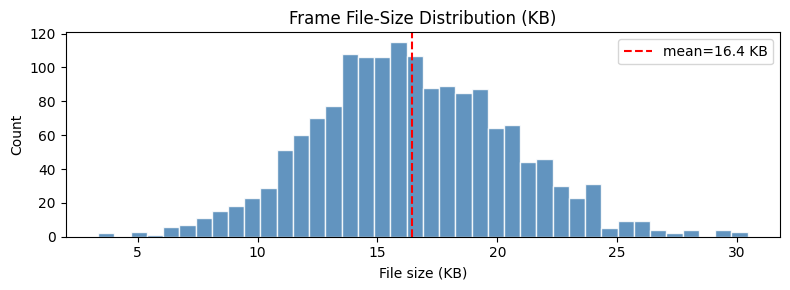

Min  : 3.3 KB
Max  : 30.4 KB
Mean : 16.4 KB
Std  : 4.1 KB


In [11]:
# File size distribution of frames
sizes_kb = [Path(r["frame_path"]).stat().st_size / 1024 for r in valid_pairs]

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(sizes_kb, bins=40, color="steelblue", edgecolor="white", alpha=0.85)
ax.axvline(np.mean(sizes_kb), color="red", linestyle="--", label=f"mean={np.mean(sizes_kb):.1f} KB")
ax.set_title("Frame File-Size Distribution (KB)")
ax.set_xlabel("File size (KB)")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Min  : {min(sizes_kb):.1f} KB")
print(f"Max  : {max(sizes_kb):.1f} KB")
print(f"Mean : {np.mean(sizes_kb):.1f} KB")
print(f"Std  : {np.std(sizes_kb):.1f} KB")

### A1-Extra: Frame Quality Analysis
Check brightness, contrast, and sharpness of the extracted frames. Low-quality frames will give M2 noisy training signal.

In [12]:
def frame_quality(path):
    """Return brightness, contrast (std), and sharpness (Laplacian variance) for a frame."""
    img = Image.open(path).convert("L")   # grayscale
    arr = np.array(img, dtype=float)
    brightness = arr.mean()
    contrast   = arr.std()
    # Laplacian variance — proxy for sharpness
    lap = np.array([
        [-1, -1, -1],
        [-1,  8, -1],
        [-1, -1, -1]
    ])
    from scipy.ndimage import convolve
    filtered = convolve(arr, lap)
    sharpness = filtered.var()
    return brightness, contrast, sharpness

# Install scipy if needed
try:
    from scipy.ndimage import convolve
except ImportError:
    import subprocess
    subprocess.run(["pip", "install", "-q", "scipy"])
    from scipy.ndimage import convolve

# Sample up to 500 frames for speed
SAMPLE_N = min(500, len(valid_pairs))
sample_for_quality = random.sample(valid_pairs, SAMPLE_N)

quality_data = []
for r in tqdm(sample_for_quality, desc="Quality analysis"):
    try:
        b, c, s = frame_quality(r["frame_path"])
        quality_data.append({"qid": r["qid"], "brightness": b, "contrast": c, "sharpness": s})
    except Exception:
        pass

print(f"Analysed {len(quality_data)} frames.")

Quality analysis: 100%|██████████| 500/500 [00:31<00:00, 16.02it/s] 

Analysed 500 frames.


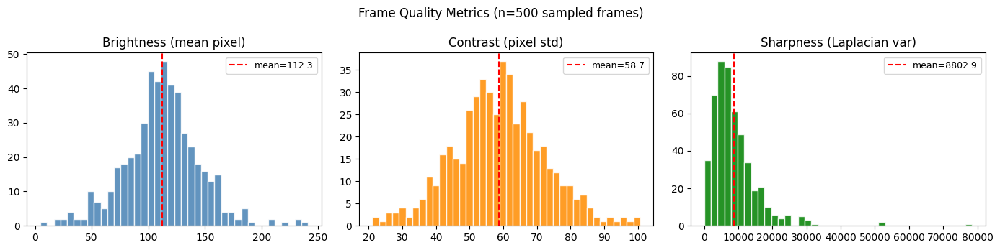

Potentially dark frames    (<30 brightness) : 7
Potentially washed-out     (>220 brightness): 3
Potentially blurry         (<p5 sharpness)  : 25


In [13]:
bright   = [d["brightness"] for d in quality_data]
contrast = [d["contrast"]   for d in quality_data]
sharp    = [d["sharpness"]  for d in quality_data]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
fig.suptitle(f"Frame Quality Metrics (n={len(quality_data)} sampled frames)", fontsize=12)

for ax, vals, label, color in zip(
    axes,
    [bright, contrast, sharp],
    ["Brightness (mean pixel)", "Contrast (pixel std)", "Sharpness (Laplacian var)"],
    ["steelblue", "darkorange", "green"]
):
    ax.hist(vals, bins=40, color=color, edgecolor="white", alpha=0.85)
    ax.axvline(np.mean(vals), color="red", linestyle="--", label=f"mean={np.mean(vals):.1f}")
    ax.set_title(label)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

# Flag potential low-quality frames
LOW_BRIGHT_THR  = 30    # near-black
HIGH_BRIGHT_THR = 220   # near-white / overexposed
LOW_SHARP_THR   = np.percentile(sharp, 5)

n_dark      = sum(1 for v in bright if v < LOW_BRIGHT_THR)
n_white     = sum(1 for v in bright if v > HIGH_BRIGHT_THR)
n_blurry    = sum(1 for v in sharp  if v < LOW_SHARP_THR)

print(f"Potentially dark frames    (<{LOW_BRIGHT_THR} brightness) : {n_dark}")
print(f"Potentially washed-out     (>{HIGH_BRIGHT_THR} brightness): {n_white}")
print(f"Potentially blurry         (<p5 sharpness)  : {n_blurry}")

---
# A2 · Inspect Sample (Frame, Query) Pairs — Semantic Alignment Audit

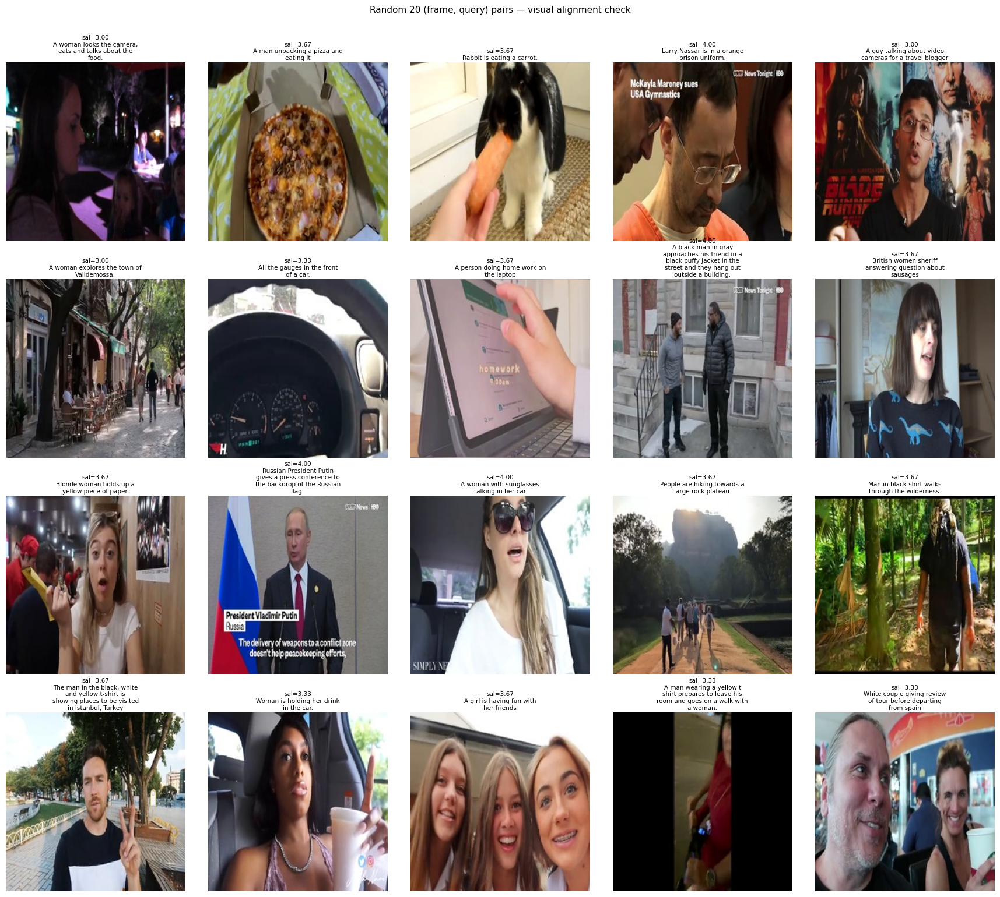

In [14]:
def show_pairs_grid(pairs, title="Random (frame, query) pairs", seed=None):
    """Display a grid of (frame, query) pairs."""
    import textwrap
    if seed is not None:
        random.seed(seed)
    sample = random.sample(pairs, min(20, len(pairs)))

    ncols = 5
    nrows = math.ceil(len(sample) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.5, nrows * 3.8))
    axes = axes.flatten()

    for i, r in enumerate(sample):
        img = Image.open(r["frame_path"])
        axes[i].imshow(img)
        axes[i].axis("off")
        wrapped = "\n".join(textwrap.wrap(r["query"], width=28))
        axes[i].set_title(
            f"sal={r['mean_saliency']:.2f}\n{wrapped}",
            fontsize=7.5, pad=3
        )

    for j in range(len(sample), len(axes)):
        axes[j].axis("off")

    fig.suptitle(title, fontsize=11, y=1.01)
    plt.tight_layout()
    plt.show()

show_pairs_grid(valid_pairs, title="Random 20 (frame, query) pairs — visual alignment check", seed=42)

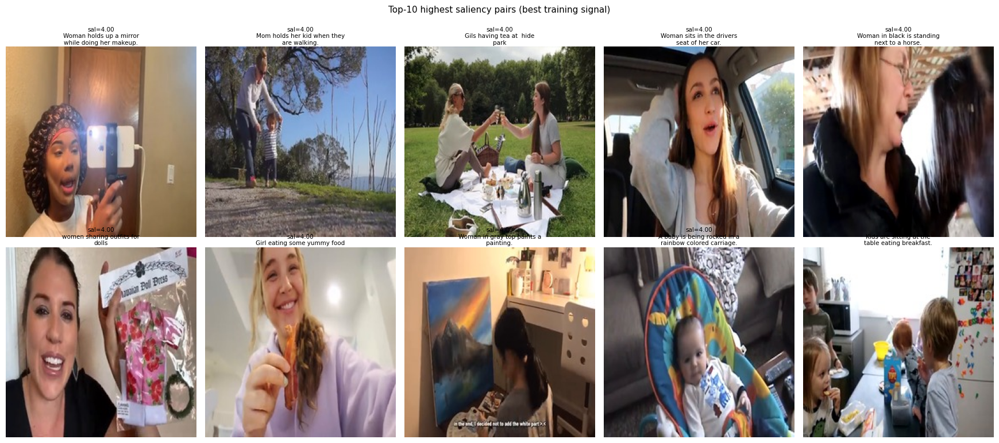

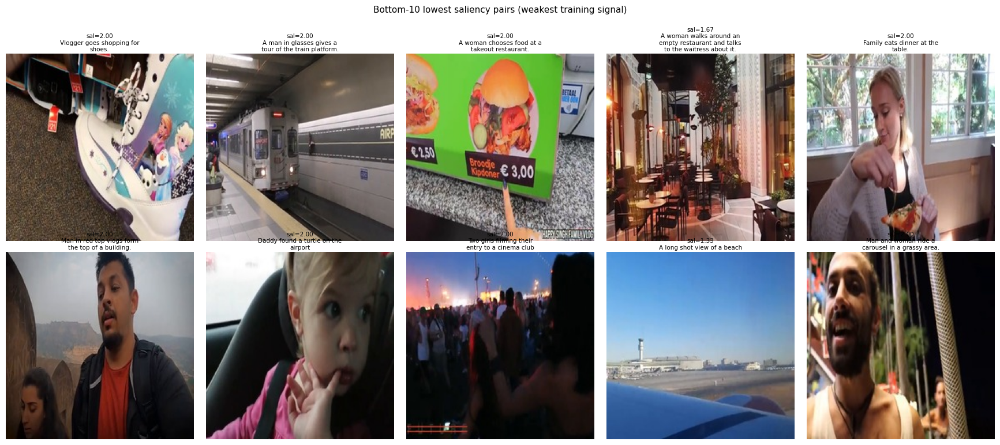

In [15]:
# Stratified review: top-saliency vs bottom-saliency pairs
sorted_by_sal = sorted(valid_pairs, key=lambda r: r["mean_saliency"], reverse=True)

top_pairs    = sorted_by_sal[:10]
bottom_pairs = sorted_by_sal[-10:]

show_pairs_grid(top_pairs,    title="Top-10 highest saliency pairs (best training signal)")
show_pairs_grid(bottom_pairs, title="Bottom-10 lowest saliency pairs (weakest training signal)")

In [16]:
# Download failure bias analysis
# Load the download log from Stage 0
if DOWNLOAD_LOG.exists():
    with open(DOWNLOAD_LOG) as f:
        dl_log = json.load(f)

    status_counts = Counter(e["status"] for e in dl_log)
    print("Download status breakdown:")
    for s, n in sorted(status_counts.items()):
        print(f"  {s:10s}: {n:5d}  ({n/len(dl_log)*100:.1f}%)")

    # Which category did failures cluster in?
    # Load train_processed to get category per vid
    train_proc  = load_jsonl(TRAIN_PROC_PATH)
    vid_to_cat  = {r["vid"]: r.get("category", "unknown") for r in train_proc}

    fail_cats   = Counter()
    ok_cats     = Counter()
    for e in dl_log:
        cat = vid_to_cat.get(e["vid"], "unknown")
        if e["status"] in ("fail", "timeout"):
            fail_cats[cat] += 1
        elif e["status"] == "ok":
            ok_cats[cat] += 1

    print("\nFailure rate by inferred category:")
    all_cats = set(fail_cats) | set(ok_cats)
    for cat in sorted(all_cats):
        total = fail_cats[cat] + ok_cats[cat]
        rate  = fail_cats[cat] / total * 100 if total else 0
        print(f"  {cat:15s}: {fail_cats[cat]:4d} fail / {total:4d} total  ({rate:.1f}% failure rate)")
else:
    print("download_log.json not found — skipping bias analysis.")

Download status breakdown:
  fail      :   302  (15.1%)
  ok        :  1648  (82.4%)
  skip      :    50  (2.5%)

Failure rate by inferred category:
  daily_vlog     :  276 fail / 1717 total  (16.1% failure rate)
  news           :    4 fail /   50 total  (8.0% failure rate)
  travel_vlog    :   22 fail /  183 total  (12.0% failure rate)


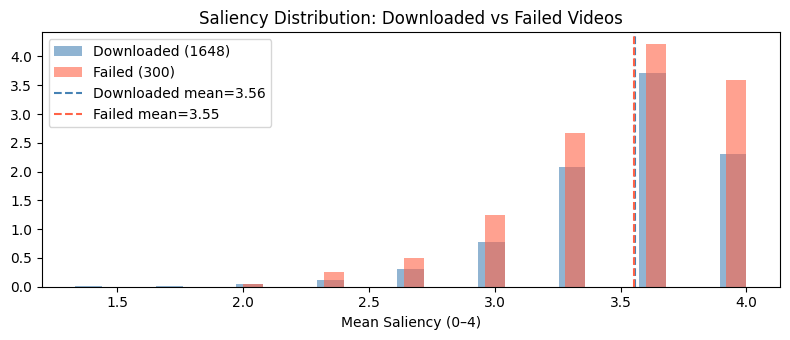

If failed mean ≈ downloaded mean → no saliency-based selection bias.


In [17]:
# Are failed downloads concentrated in certain saliency ranges?
# (If high-saliency videos are more likely to be deleted/private, we lose our best training signal)
if DOWNLOAD_LOG.exists():
    failed_vids = {e["vid"] for e in dl_log if e["status"] in ("fail", "timeout")}
    success_vids = {e["vid"] for e in dl_log if e["status"] == "ok"}

    vid_to_sal = {r["vid"]: r.get("mean_saliency") for r in train_proc if r.get("mean_saliency")}

    failed_sals  = [vid_to_sal[v] for v in failed_vids  if v in vid_to_sal]
    success_sals = [vid_to_sal[v] for v in success_vids if v in vid_to_sal]

    if failed_sals and success_sals:
        fig, ax = plt.subplots(figsize=(8, 3.5))
        ax.hist(success_sals, bins=25, alpha=0.6, label=f"Downloaded ({len(success_sals)})",
                color="steelblue", density=True)
        ax.hist(failed_sals,  bins=25, alpha=0.6, label=f"Failed ({len(failed_sals)})",
                color="tomato", density=True)
        ax.axvline(np.mean(success_sals), color="steelblue", linestyle="--",
                   label=f"Downloaded mean={np.mean(success_sals):.2f}")
        ax.axvline(np.mean(failed_sals), color="tomato", linestyle="--",
                   label=f"Failed mean={np.mean(failed_sals):.2f}")
        ax.set_title("Saliency Distribution: Downloaded vs Failed Videos")
        ax.set_xlabel("Mean Saliency (0–4)")
        ax.legend()
        plt.tight_layout()
        plt.show()
        print("If failed mean ≈ downloaded mean → no saliency-based selection bias.")
    else:
        print("Not enough data for saliency bias plot.")

# A3: Train/Val Split for M2 (90/10)

In [18]:
# 90/10 split, fixed seed, stratified by saliency quintile
# Stratifying by saliency ensures both train and val have the same range of
# signal quality — we don't want val to be accidentally all easy or all hard.

SEED       = 42
VAL_RATIO  = 0.10

random.seed(SEED)

# Bin pairs into 5 saliency quintiles
n = len(valid_pairs)
sorted_by_sal = sorted(valid_pairs, key=lambda r: r["mean_saliency"])
quintile_size = n // 5

train_qids = []
val_qids   = []

for q in range(5):
    start = q * quintile_size
    end   = (q + 1) * quintile_size if q < 4 else n
    bucket = sorted_by_sal[start:end]
    random.shuffle(bucket)
    n_val   = max(1, round(len(bucket) * VAL_RATIO))
    val_qids.extend(r["qid"] for r in bucket[:n_val])
    train_qids.extend(r["qid"] for r in bucket[n_val:])

# Build split sets
val_set   = set(val_qids)
train_set = set(train_qids)

m2_train = [r for r in valid_pairs if r["qid"] in train_set]
m2_val   = [r for r in valid_pairs if r["qid"] in val_set]

print(f"M2 train split : {len(m2_train):,} pairs  ({len(m2_train)/n*100:.1f}%)")
print(f"M2 val   split : {len(m2_val):,} pairs  ({len(m2_val)/n*100:.1f}%)")
print(f"Total          : {len(m2_train)+len(m2_val):,}")

M2 train split : 1,448 pairs  (90.0%)
M2 val   split : 160 pairs  (10.0%)
Total          : 1,608


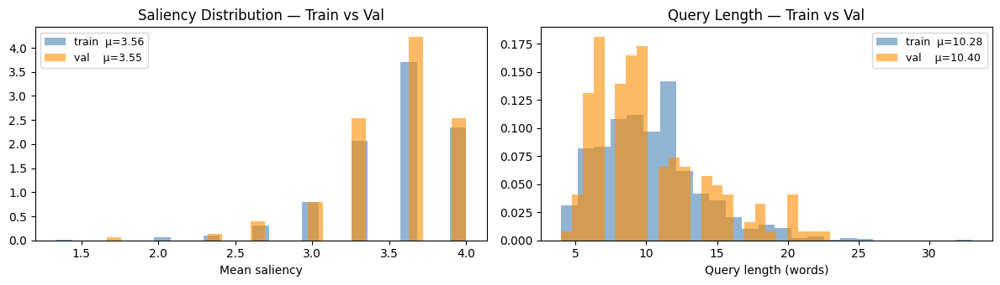

Train saliency — mean: 3.561  std: 0.390
Val   saliency — mean: 3.550  std: 0.397
✓ Split is well-balanced if the two means are close.


In [19]:
# Validate split quality
train_sal  = [r["mean_saliency"] for r in m2_train]
val_sal    = [r["mean_saliency"] for r in m2_val]

train_qlen = [len(r["query"].split()) for r in m2_train]
val_qlen   = [len(r["query"].split()) for r in m2_val]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

for ax, t_vals, v_vals, xlabel, title in zip(
    axes,
    [train_sal, train_qlen],
    [val_sal,   val_qlen],
    ["Mean saliency", "Query length (words)"],
    ["Saliency Distribution — Train vs Val", "Query Length — Train vs Val"]
):
    ax.hist(t_vals, bins=25, alpha=0.6, color="steelblue", density=True, label=f"train  μ={np.mean(t_vals):.2f}")
    ax.hist(v_vals, bins=25, alpha=0.6, color="darkorange", density=True, label=f"val    μ={np.mean(v_vals):.2f}")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

print("Train saliency — mean: {:.3f}  std: {:.3f}".format(np.mean(train_sal), np.std(train_sal)))
print("Val   saliency — mean: {:.3f}  std: {:.3f}".format(np.mean(val_sal),   np.std(val_sal)))
print("✓ Split is well-balanced if the two means are close.")

In [20]:
# Save split indices to disk
split_record = {
    "seed"         : SEED,
    "val_ratio"    : VAL_RATIO,
    "n_total"      : len(valid_pairs),
    "n_train"      : len(m2_train),
    "n_val"        : len(m2_val),
    "train_qids"   : sorted(train_qids),
    "val_qids"     : sorted(val_qids),
}

with open(SPLIT_INDICES_PATH, "w") as f:
    json.dump(split_record, f, indent=2)

print(f"Split indices saved → {SPLIT_INDICES_PATH.name}")
print(f"  train: {split_record['n_train']} qids")
print(f"  val  : {split_record['n_val']} qids")

Split indices saved → m2_split_indices.json
  train: 1448 qids
  val  : 160 qids


---
# A4 · Audit Query Vocabulary

In [22]:
# Raw vocabulary (word-level)
all_queries = [r["query"] for r in valid_pairs]

# Tokenize as plain words (lowercase, strip punctuation)
word_counter = Counter()
for q in all_queries:
    words = re.findall(r"[a-z']+", q.lower())
    word_counter.update(words)

vocab_size    = len(word_counter)
total_tokens  = sum(word_counter.values())
mean_q_len    = np.mean([len(re.findall(r"[a-z']+", q.lower())) for q in all_queries])
unique_q_frac = len(set(all_queries)) / len(all_queries)

print(f"Total queries           : {len(all_queries):,}")
print(f"Unique queries          : {len(set(all_queries)):,}  ({unique_q_frac*100:.1f}% unique)")
print(f"Vocabulary size (words) : {vocab_size:,}")
print(f"Total word tokens       : {total_tokens:,}")
print(f"Mean query length       : {mean_q_len:.1f} words")

print("\nTop-30 most frequent words:")
for word, cnt in word_counter.most_common(30):
    print(f"  {word:20s}: {cnt:5d}")

Total queries           : 1,608
Unique queries          : 1,607  (99.9% unique)
Vocabulary size (words) : 2,620
Total word tokens       : 16,557
Mean query length       : 10.3 words

Top-30 most frequent words:
  a                   :  1839
  in                  :   669
  the                 :   614
  woman               :   523
  and                 :   397
  is                  :   376
  of                  :   348
  man                 :   303
  on                  :   280
  her                 :   218
  with                :   218
  to                  :   216
  are                 :   154
  at                  :   130
  girl                :   107
  talking             :   102
  white               :   100
  black               :    97
  from                :    89
  while               :    88
  showing             :    87
  two                 :    86
  top                 :    84
  up                  :    84
  camera              :    78
  an                  :    77
  car    

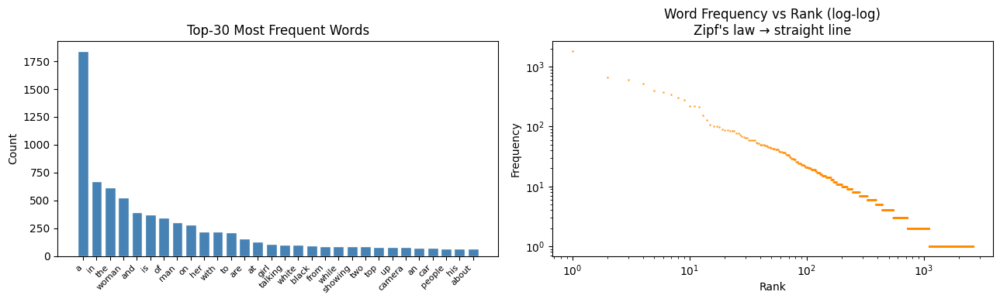

In [23]:
# Word frequency distribution (log-log → should show Zipf's law)
freq_vals  = sorted(word_counter.values(), reverse=True)
ranks      = list(range(1, len(freq_vals) + 1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(range(1, 31), [word_counter[w] for w, _ in word_counter.most_common(30)],
            color="steelblue", edgecolor="white")
axes[0].set_xticks(range(1, 31))
axes[0].set_xticklabels([w for w, _ in word_counter.most_common(30)], rotation=45, ha="right", fontsize=8)
axes[0].set_title("Top-30 Most Frequent Words")
axes[0].set_ylabel("Count")

axes[1].loglog(ranks, freq_vals, ".", markersize=2, color="darkorange", alpha=0.6)
axes[1].set_title("Word Frequency vs Rank (log-log)\nZipf's law → straight line")
axes[1].set_xlabel("Rank")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [24]:
# GPT-2 sub-word tokenization analysis
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token

token_lengths  = []
unk_count      = 0
MAX_SEQ_LEN    = 64   # proposed max input length for M2 decoder
too_long_count = 0

for q in tqdm(all_queries, desc="GPT-2 tokenizing"):
    ids = tokenizer.encode(q, add_special_tokens=True)
    token_lengths.append(len(ids))
    if len(ids) > MAX_SEQ_LEN:
        too_long_count += 1
    # GPT-2 has no true UNK; all chars are covered by BPE
    # Check for the replacement character (U+FFFD) as proxy for encoding issues
    if "\ufffd" in tokenizer.decode(ids):
        unk_count += 1

print(f"Token length stats (GPT-2 BPE, incl. EOS):")
print(f"  Min    : {min(token_lengths)}")
print(f"  Max    : {max(token_lengths)}")
print(f"  Mean   : {np.mean(token_lengths):.1f}")
print(f"  Std    : {np.std(token_lengths):.1f}")
print(f"  p95    : {np.percentile(token_lengths, 95):.0f}")
print(f"  p99    : {np.percentile(token_lengths, 99):.0f}")
print(f"  > {MAX_SEQ_LEN} tokens : {too_long_count} ({too_long_count/len(all_queries)*100:.1f}%)")
print(f"  Encoding issues    : {unk_count}")
print(f"\n→ Recommended max_seq_len for M2 decoder: {int(np.percentile(token_lengths, 99)) + 2}")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

GPT-2 tokenizing: 100%|██████████| 1608/1608 [00:00<00:00, 6975.92it/s]

Token length stats (GPT-2 BPE, incl. EOS):
  Min    : 4
  Max    : 35
  Mean   : 11.7
  Std    : 3.9
  p95    : 19
  p99    : 23
  > 64 tokens : 0 (0.0%)
  Encoding issues    : 0

→ Recommended max_seq_len for M2 decoder: 25


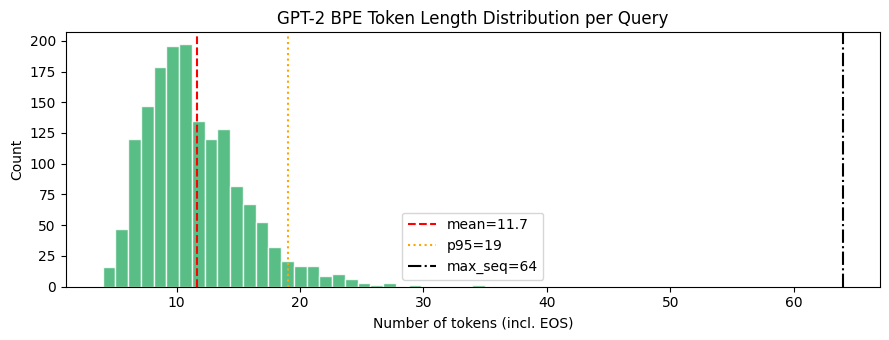

In [25]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(token_lengths, bins=30, color="mediumseagreen", edgecolor="white", alpha=0.85)
ax.axvline(np.mean(token_lengths), color="red", linestyle="--", label=f"mean={np.mean(token_lengths):.1f}")
ax.axvline(np.percentile(token_lengths, 95), color="orange", linestyle=":",
           label=f"p95={np.percentile(token_lengths, 95):.0f}")
ax.axvline(MAX_SEQ_LEN, color="black", linestyle="-.", label=f"max_seq={MAX_SEQ_LEN}")
ax.set_title("GPT-2 BPE Token Length Distribution per Query")
ax.set_xlabel("Number of tokens (incl. EOS)")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.show()

In [27]:
# Query semantic mini-clustering via TF-IDF + top bigrams
# Gives a rough sense of the semantic territory M2 must learn to generate.

from collections import Counter

# Bigram extraction
def get_bigrams(text):
    words = re.findall(r"[a-z']+", text.lower())
    return [(words[i], words[i+1]) for i in range(len(words)-1)]

bigram_counter = Counter()
for q in all_queries:
    bigram_counter.update(get_bigrams(q))

# Filter out bigrams starting/ending with stopwords
STOPWORDS = {"a","an","the","is","are","was","were","be","been","being",
             "to","of","in","at","on","and","or","with","his","her",
             "he","she","they","it","that","this","from","as"}

filtered_bigrams = {
    bg: cnt for bg, cnt in bigram_counter.items()
    if bg[0] not in STOPWORDS and bg[1] not in STOPWORDS
}

top_bigrams = sorted(filtered_bigrams.items(), key=lambda x: x[1], reverse=True)[:30]

print("Top-30 content bigrams in query corpus:")
for (w1, w2), cnt in top_bigrams:
    print(f"  {w1} {w2:30s}: {cnt}")

Top-30 content bigrams in query corpus:
  blonde woman                         : 26
  two women                         : 21
  young woman                         : 18
  talks about                         : 18
  hotel room                          : 17
  two men                           : 17
  man talks                         : 15
  black top                           : 15
  woman talks                         : 15
  woman wearing                       : 15
  t shirt                         : 15
  white top                           : 14
  holds up                            : 14
  while talking                       : 14
  woman walks                         : 14
  walks around                        : 14
  shows off                           : 14
  talking about                         : 14
  woman wears                         : 13
  man wearing                       : 13
  walks down                          : 12
  woman holds                         : 12
  sharing some         

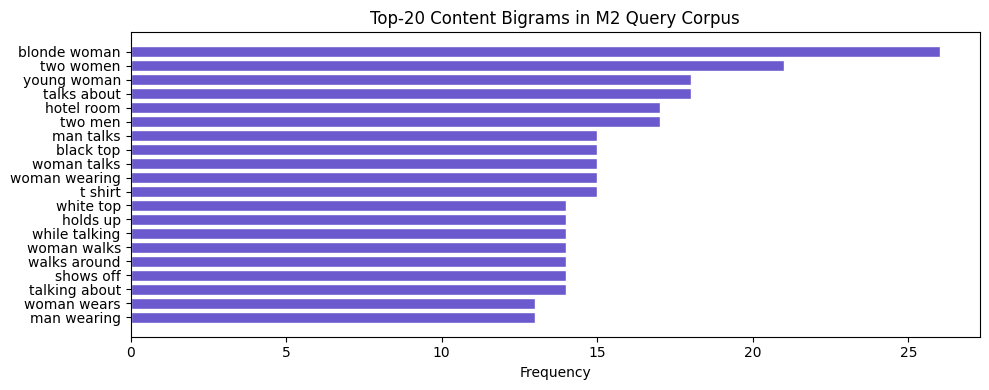

In [28]:
labels = [f"{w1} {w2}" for (w1, w2), _ in top_bigrams[:20]]
counts = [cnt for _, cnt in top_bigrams[:20]]

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(labels[::-1], counts[::-1], color="slateblue", edgecolor="white")
ax.set_title("Top-20 Content Bigrams in M2 Query Corpus")
ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()

In [29]:
# Save vocabulary stats for reference in Phase B
recommended_max_len = int(np.percentile(token_lengths, 99)) + 2

vocab_stats = {
    "n_queries"            : len(all_queries),
    "n_unique_queries"     : len(set(all_queries)),
    "word_vocab_size"      : vocab_size,
    "mean_word_length"     : round(float(mean_q_len), 2),
    "gpt2_token_mean"      : round(float(np.mean(token_lengths)), 2),
    "gpt2_token_std"       : round(float(np.std(token_lengths)), 2),
    "gpt2_token_p95"       : int(np.percentile(token_lengths, 95)),
    "gpt2_token_p99"       : int(np.percentile(token_lengths, 99)),
    "recommended_max_len"  : recommended_max_len,
    "queries_exceeding_max": too_long_count,
    "pii_hits"             : {k: len(v) for k, v in pii_hits.items()},
    "offensive_hits"       : len(offensive_hits),
    "top_30_words"         : [(w, c) for w, c in word_counter.most_common(30)],
    "top_20_bigrams"       : [({"bigram": f"{w1} {w2}", "count": c}) for (w1,w2),c in top_bigrams[:20]],
}

with open(VOCAB_STATS_PATH, "w") as f:
    json.dump(vocab_stats, f, indent=2)

print(f"Vocabulary stats saved → {VOCAB_STATS_PATH.name}")
print(f"\n→ Use max_seq_len = {recommended_max_len} in Phase B M2Dataset")

Vocabulary stats saved → m2_vocab_stats.json

→ Use max_seq_len = 25 in Phase B M2Dataset


### Phase A Summary
GPT-2 BPE covers all tokens in the corpus with no UNK issues. The p99 token length and the recommended `max_seq_len` are printed above and saved to `m2_vocab_stats.json`. Use that value when configuring the M2Dataset tokenizer in Phase B.

# B:  Augmentation Pipeline

Two transforms are built:
- `train_transform` applies randomised augmentations that simulate real YouTube thumbnail
  characteristics: colour saturation boosts, sharpening, and random crops with resizing.
  A grey-bar masking step simulates text overlay regions that appear on many thumbnails.
- `val_transform` is deterministic: centre-crop to the CLIP expected 224x224 input.

In [31]:
M2_PAIRS_PATH  = PROCESSED_DIR / "m2_train_pairs.jsonl"
SPLIT_PATH     = PROCESSED_DIR / "m2_split_indices.json"
VOCAB_STATS    = PROCESSED_DIR / "m2_vocab_stats.json"

# Load Phase A outputs
def load_jsonl(path):
    with open(path) as f:
        return [json.loads(l) for l in f if l.strip()]

all_pairs = load_jsonl(M2_PAIRS_PATH)

with open(SPLIT_PATH) as f:
    split = json.load(f)

with open(VOCAB_STATS) as f:
    vocab_stats = json.load(f)

train_qids = set(split["train_qids"])
val_qids   = set(split["val_qids"])

train_pairs = [r for r in all_pairs if r["qid"] in train_qids]
val_pairs   = [r for r in all_pairs if r["qid"] in val_qids]

MAX_SEQ_LEN = vocab_stats["recommended_max_len"]  # 25

print(f"Train pairs  : {len(train_pairs):,}")
print(f"Val pairs    : {len(val_pairs):,}")
print(f"max_seq_len  : {MAX_SEQ_LEN}  (from Phase A vocab audit)")

Train pairs  : 1,448
Val pairs    : 160
max_seq_len  : 25  (from Phase A vocab audit)


In [32]:
# CLIP's own normalisation constants
CLIP_MEAN = (0.48145466, 0.4578275,  0.40821073)
CLIP_STD  = (0.26862954, 0.26130258, 0.27577711)


class TextBarMask:
    """Randomly paste a grey rectangle at the bottom of the image
    to simulate the text-overlay bars common on YouTube thumbnails.
    Applied with probability p."""

    def __init__(self, p=0.3, height_frac=(0.10, 0.25)):
        self.p = p
        self.height_frac = height_frac

    def __call__(self, img):
        if random.random() > self.p:
            return img
        img = img.copy()
        w, h = img.size
        bar_h = int(random.uniform(*self.height_frac) * h)
        # dark semi-transparent bar: fill with a mid-grey solid
        from PIL import ImageDraw
        draw = ImageDraw.Draw(img)
        draw.rectangle([0, h - bar_h, w, h], fill=(40, 40, 40))
        return img


class FaceCropSimulator:
    """With probability p, randomly zoom into the upper-centre third
    of the image, simulating face-zoomed thumbnails."""

    def __init__(self, p=0.2):
        self.p = p

    def __call__(self, img):
        if random.random() > self.p:
            return img
        w, h = img.size
        left   = int(0.15 * w)
        right  = int(0.85 * w)
        top    = 0
        bottom = int(0.65 * h)
        return img.crop((left, top, right, bottom))


train_transform = transforms.Compose([
    # Thumbnail-style augmentations first (operate on PIL images)
    TextBarMask(p=0.30),
    FaceCropSimulator(p=0.20),
    # Standard spatial and colour augmentations
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.5,   # higher saturation boost: thumbnails are often over-saturated
        hue=0.05,
    ),
    transforms.RandomAdjustSharpness(sharpness_factor=2.0, p=0.4),
    transforms.ToTensor(),
    transforms.Normalize(CLIP_MEAN, CLIP_STD),
])

val_transform = transforms.Compose([
    transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(CLIP_MEAN, CLIP_STD),
])

print("Augmentation pipeline defined.")
print("  train_transform : RandomResizedCrop + HFlip + ColorJitter + Sharpness + TextBarMask + FaceCropSimulator")
print("  val_transform   : Resize + CenterCrop (deterministic)")

Augmentation pipeline defined.
  train_transform : RandomResizedCrop + HFlip + ColorJitter + Sharpness + TextBarMask + FaceCropSimulator
  val_transform   : Resize + CenterCrop (deterministic)


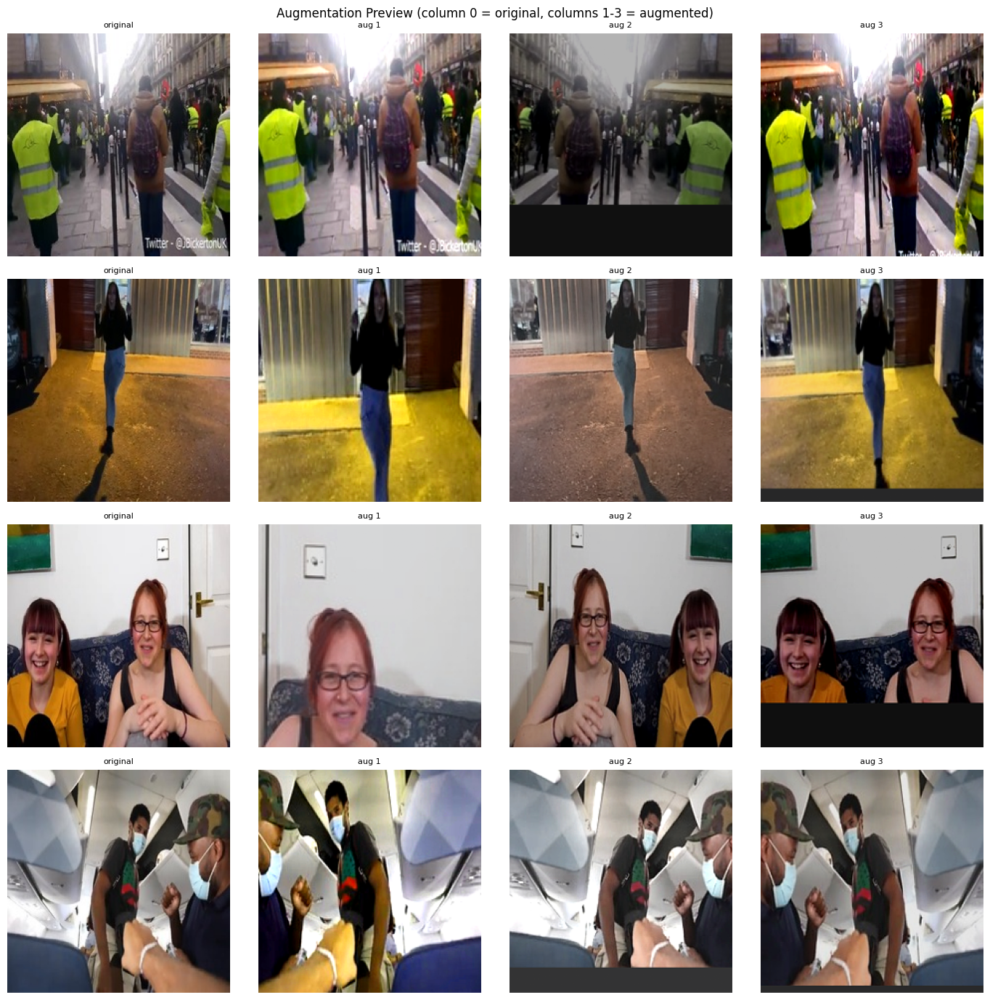

In [33]:
# Visualise the augmentation pipeline on 4 random training frames
# Each row: original | aug1 | aug2 | aug3

def denorm(tensor):
    """Reverse CLIP normalisation for display."""
    mean = torch.tensor(CLIP_MEAN).view(3, 1, 1)
    std  = torch.tensor(CLIP_STD).view(3, 1, 1)
    return (tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

sample_pairs = random.sample(train_pairs, 4)
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
fig.suptitle("Augmentation Preview (column 0 = original, columns 1-3 = augmented)", fontsize=12)

for row, pair in enumerate(sample_pairs):
    img = Image.open(pair["frame_path"]).convert("RGB")
    axes[row, 0].imshow(img.resize((224, 224)))
    axes[row, 0].set_title("original", fontsize=8)
    for col in range(1, 4):
        aug = denorm(train_transform(img))
        axes[row, col].imshow(aug)
        axes[row, col].set_title(f"aug {col}", fontsize=8)
    axes[row, 0].set_ylabel(
        pair["query"][:40] + ("..." if len(pair["query"]) > 40 else ""),
        fontsize=7, rotation=0, labelpad=120, va="center"
    )

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

# B1  M2Dataset

In [34]:
class M2Dataset(Dataset):
    """
    Returns one item per (frame, query) pair.

    pixel_values : (3, 224, 224) float32 tensor, CLIP-normalised
    input_ids    : (max_seq_len,) int64  GPT-2 token ids with BOS prepended
    labels       : (max_seq_len,) int64  same as input_ids but padded positions
                   set to -100 so cross-entropy ignores them
    """

    def __init__(self, pairs, tokenizer, max_seq_len, transform):
        self.pairs       = pairs
        self.tokenizer   = tokenizer
        self.max_seq_len = max_seq_len
        self.transform   = transform

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        pair  = self.pairs[idx]
        query = pair["query"]

        # Image
        img          = Image.open(pair["frame_path"]).convert("RGB")
        pixel_values = self.transform(img)

        # Tokenise query: prepend BOS, truncate/pad to max_seq_len
        tokens = self.tokenizer.encode(query)
        tokens = [self.tokenizer.bos_token_id] + tokens
        tokens = tokens[: self.max_seq_len]

        pad_id    = self.tokenizer.eos_token_id  # GPT-2 has no dedicated PAD; use EOS
        pad_len   = self.max_seq_len - len(tokens)
        input_ids = tokens + [pad_id] * pad_len

        # Labels: -100 on padding positions so loss ignores them
        labels    = tokens + [-100] * pad_len

        return {
            "pixel_values": pixel_values,
            "input_ids"   : torch.tensor(input_ids, dtype=torch.long),
            "labels"      : torch.tensor(labels,    dtype=torch.long),
        }


# Initialise tokenizer
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token

train_dataset = M2Dataset(train_pairs, tokenizer, MAX_SEQ_LEN, train_transform)
val_dataset   = M2Dataset(val_pairs,   tokenizer, MAX_SEQ_LEN, val_transform)

print(f"Train dataset : {len(train_dataset):,} samples")
print(f"Val dataset   : {len(val_dataset):,} samples")

# Inspect one item
item = train_dataset[0]
print(f"\nSample item shapes:")
for k, v in item.items():
    print(f"  {k:15s}: {tuple(v.shape)}  dtype={v.dtype}")

Train dataset : 1,448 samples
Val dataset   : 160 samples

Sample item shapes:
  pixel_values   : (3, 224, 224)  dtype=torch.float32
  input_ids      : (25,)  dtype=torch.int64
  labels         : (25,)  dtype=torch.int64


In [35]:
import time
# Dataloader throughput benchmark
# Measures samples/sec at different num_workers settings so we can
# pick the fastest configuration before committing to a full training run.

BATCH_SIZE = 32

print("Dataloader throughput benchmark (50 batches each)")
print(f"  Batch size: {BATCH_SIZE}")

for nw in [0, 2, 4]:
    loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                        shuffle=True, num_workers=nw, pin_memory=True)
    t0 = time.time()
    count = 0
    for i, batch in enumerate(loader):
        count += batch["pixel_values"].shape[0]
        if i >= 49:
            break
    elapsed = time.time() - t0
    print(f"  num_workers={nw}  ->  {count / elapsed:.0f} samples/sec  ({elapsed:.1f}s for 50 batches)")

# Use num_workers=2 as default unless benchmark shows otherwise
NUM_WORKERS = 2

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

print(f"\nFinal loaders: batch_size={BATCH_SIZE}  num_workers={NUM_WORKERS}")
print(f"  train batches : {len(train_loader)}")
print(f"  val batches   : {len(val_loader)}")

Dataloader throughput benchmark (50 batches each)
  Batch size: 32
  num_workers=0  ->  77 samples/sec  (18.7s for 50 batches)
  num_workers=2  ->  90 samples/sec  (16.1s for 50 batches)


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


  num_workers=4  ->  98 samples/sec  (14.8s for 50 batches)

Final loaders: batch_size=32  num_workers=2
  train batches : 46
  val batches   : 5


# C:  M2 Model Architecture

Architecture: CLIP ViT-B/32 visual encoder (frozen initially) -> linear projection
layer (768 -> 768) -> GPT-2 cross-attention prefix.

The image embedding from CLIP is projected into GPT-2's embedding space and
prepended as a prefix token sequence. GPT-2 then attends to this prefix while
generating the query tokens via its standard causal language modelling head.

This is the ClipCap approach (Mokady et al., 2021) which has been shown to work
well for image-conditioned text generation with small training sets because the
visual projection is the only new component that needs to be learned from scratch.

In [36]:
class M2Model(nn.Module):
    """
    CLIP visual encoder + linear projection + GPT-2 decoder.

    At train time:
        forward(pixel_values, input_ids, labels) -> cross-entropy loss

    At inference time:
        generate(pixel_values) -> token ids (greedy or beam)
    """

    def __init__(
        self,
        clip_model_name   = "ViT-B/32",
        gpt2_model_name   = "gpt2",
        prefix_length     = 10,
        freeze_clip       = True,
    ):
        super().__init__()

        self.prefix_length = prefix_length

        # CLIP visual encoder
        clip_model, _ = clip.load(clip_model_name, device="cpu")
        self.clip_encoder = clip_model.visual
        self.clip_dim     = self.clip_encoder.output_dim  # 512 for ViT-B/32

        if freeze_clip:
            for param in self.clip_encoder.parameters():
                param.requires_grad = False

        # GPT-2 decoder
        self.gpt2      = GPT2LMHeadModel.from_pretrained(gpt2_model_name)
        self.gpt2_dim  = self.gpt2.config.n_embd  # 768 for GPT-2 base

        # Projection: maps CLIP embedding to a sequence of prefix_length GPT-2 tokens
        # Using a two-layer MLP with GELU gives slightly better results than a single
        # linear layer at the cost of a small number of parameters.
        self.projection = nn.Sequential(
            nn.Linear(self.clip_dim, self.gpt2_dim * prefix_length),
            nn.GELU(),
            nn.Linear(self.gpt2_dim * prefix_length, self.gpt2_dim * prefix_length),
        )

    def encode_image(self, pixel_values):
        """Return (B, prefix_length, gpt2_dim) prefix embeddings."""
        with torch.no_grad() if not self.clip_encoder.training else torch.enable_grad():
            clip_emb = self.clip_encoder(pixel_values.to(self.clip_encoder.conv1.weight.dtype))
        clip_emb  = clip_emb.float()
        prefix    = self.projection(clip_emb)                     # (B, gpt2_dim * prefix_length)
        prefix    = prefix.view(-1, self.prefix_length, self.gpt2_dim)  # (B, prefix_length, gpt2_dim)
        return prefix

    def forward(self, pixel_values, input_ids, labels=None):
        prefix    = self.encode_image(pixel_values)               # (B, prefix_length, D)
        token_emb = self.gpt2.transformer.wte(input_ids)          # (B, seq_len, D)
        inputs_emb = torch.cat([prefix, token_emb], dim=1)        # (B, prefix_length + seq_len, D)

        # Shift labels to account for prefix tokens
        if labels is not None:
            prefix_labels = torch.full(
                (labels.shape[0], self.prefix_length), -100,
                dtype=labels.dtype, device=labels.device
            )
            shifted_labels = torch.cat([prefix_labels, labels], dim=1)
        else:
            shifted_labels = None

        out  = self.gpt2(inputs_embeds=inputs_emb, labels=shifted_labels)
        return out

    def generate(self, pixel_values, tokenizer, max_new_tokens=25, beam_size=1):
        """Decode a query string from an image.

        beam_size=1  -> greedy decoding (fast)
        beam_size>1  -> beam search (better quality, slower)
        """
        self.eval()
        with torch.no_grad():
            prefix = self.encode_image(pixel_values)  # (B, prefix_length, D)

            # Prime with BOS token
            bos = torch.tensor([[tokenizer.bos_token_id]] * pixel_values.shape[0],
                               device=DEVICE)
            bos_emb = self.gpt2.transformer.wte(bos)   # (B, 1, D)
            generated_emb = torch.cat([prefix, bos_emb], dim=1)

            generated_ids = []
            past_key_values = None

            for _ in range(max_new_tokens):
                out = self.gpt2(
                    inputs_embeds=generated_emb,
                    past_key_values=past_key_values,
                    use_cache=True,
                )
                logits         = out.logits[:, -1, :]  # (B, vocab)
                past_key_values = out.past_key_values

                if beam_size == 1:
                    next_id = logits.argmax(dim=-1, keepdim=True)  # (B, 1)
                else:
                    # Simplified top-k sampling as a beam proxy (full beam search
                    # across batches is complex; use HuggingFace generate for production)
                    probs   = F.softmax(logits / 0.7, dim=-1)
                    next_id = torch.multinomial(probs, 1)

                generated_ids.append(next_id)
                # EOS check: stop if all items in batch hit EOS
                if (next_id == tokenizer.eos_token_id).all():
                    break

                next_emb      = self.gpt2.transformer.wte(next_id)
                generated_emb = next_emb  # only need the last token since we use cache

            ids = torch.cat(generated_ids, dim=1).cpu().tolist()  # (B, gen_len)

        queries = []
        for seq in ids:
            # Trim at first EOS
            try:
                eos_pos = seq.index(tokenizer.eos_token_id)
                seq = seq[:eos_pos]
            except ValueError:
                pass
            queries.append(tokenizer.decode(seq, skip_special_tokens=True).strip())
        return queries


print("M2Model class defined.")

M2Model class defined.


In [37]:
# Instantiate model and audit parameter counts + memory footprint

model = M2Model(
    clip_model_name = "ViT-B/32",
    gpt2_model_name = "gpt2",
    prefix_length   = 10,
    freeze_clip     = True,
).to(DEVICE)

def count_params(m):
    total     = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return total, trainable

total_clip, train_clip = count_params(model.clip_encoder)
total_gpt2, train_gpt2 = count_params(model.gpt2)
total_proj, train_proj = count_params(model.projection)
total_all,  train_all  = count_params(model)

print("Parameter counts")
print(f"  CLIP encoder  : {total_clip/1e6:.1f}M total  {train_clip/1e6:.1f}M trainable  (frozen)")
print(f"  GPT-2 decoder : {total_gpt2/1e6:.1f}M total  {train_gpt2/1e6:.1f}M trainable")
print(f"  Projection    : {total_proj/1e6:.3f}M total  {train_proj/1e6:.3f}M trainable")
print(f"  TOTAL         : {total_all/1e6:.1f}M total  {train_all/1e6:.1f}M trainable")

# Rough memory estimate for one forward pass
param_bytes = train_all * 4  # float32
grad_bytes  = train_all * 4
adam_bytes  = train_all * 8  # two momentum terms
total_gb    = (param_bytes + grad_bytes + adam_bytes) / 1e9
print(f"\nEstimated optimiser memory : {total_gb:.2f} GB  (params + grads + Adam moments, float32)")
print("Activations and batch buffers are additional.")

# Forward pass smoke test
dummy_px  = torch.randn(2, 3, 224, 224).to(DEVICE)
dummy_ids = torch.randint(0, 50257, (2, MAX_SEQ_LEN)).to(DEVICE)
dummy_lbl = dummy_ids.clone()
out = model(dummy_px, dummy_ids, dummy_lbl)
print(f"\nForward pass smoke test OK — loss shape: {out.loss.shape}  loss value: {out.loss.item():.3f}")

100%|████████████████████████████████████████| 338M/338M [00:03<00:00, 103MiB/s]


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Parameter counts
  CLIP encoder  : 87.8M total  0.0M trainable  (frozen)
  GPT-2 decoder : 124.4M total  124.4M trainable
  Projection    : 62.930M total  62.930M trainable
  TOTAL         : 275.2M total  187.4M trainable

Estimated optimiser memory : 3.00 GB  (params + grads + Adam moments, float32)
Activations and batch buffers are additional.


`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.



Forward pass smoke test OK — loss shape: torch.Size([])  loss value: 18.541


# B3  Training Loop

In [38]:
# Evaluation helpers: BLEU-4 and ROUGE-L
# These run on the validation set at the end of each epoch.

def evaluate_metrics(model, loader, tokenizer, n_samples=None):
    """Compute BLEU-4 and ROUGE-L on loader.

    n_samples: if set, stop after n_samples to keep eval fast during early epochs.
    """
    model.eval()
    hypotheses = []
    references = []
    val_loss   = 0.0
    n_batches  = 0

    scorer = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

    with torch.no_grad():
        for batch in loader:
            px  = batch["pixel_values"].to(DEVICE)
            ids = batch["input_ids"].to(DEVICE)
            lbl = batch["labels"].to(DEVICE)

            out       = model(px, ids, lbl)
            val_loss += out.loss.item()
            n_batches += 1

            # Generate queries for BLEU/ROUGE
            gen_queries = model.generate(px, tokenizer, max_new_tokens=MAX_SEQ_LEN)
            # Decode ground-truth (strip BOS, EOS, padding)
            for i, seq in enumerate(ids.cpu().tolist()):
                clean = [t for t in seq if t not in (
                    tokenizer.bos_token_id, tokenizer.eos_token_id
                )]
                references.append(tokenizer.decode(clean, skip_special_tokens=True).strip())
            hypotheses.extend(gen_queries)

            if n_samples and len(hypotheses) >= n_samples:
                break

    # BLEU-4
    bleu = sacrebleu.corpus_bleu(hypotheses, [references]).score

    # ROUGE-L (mean F1)
    rouge_scores = [scorer.score(ref, hyp)["rougeL"].fmeasure
                    for ref, hyp in zip(references, hypotheses)]
    rouge_l = float(np.mean(rouge_scores)) * 100

    avg_loss = val_loss / n_batches
    return avg_loss, bleu, rouge_l


print("Evaluation helpers defined.")

Evaluation helpers defined.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


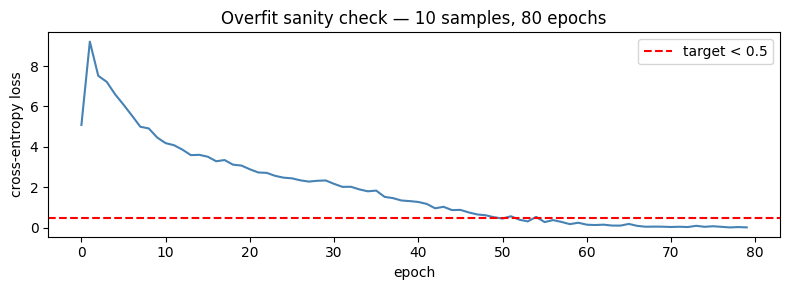

Final overfit loss: 0.0213  [PASS]


In [39]:
# Sanity check: overfit on 10 training samples
# The loss should drop well below 1.0 within ~50 epochs.
# If it does not, there is a bug in the data pipeline or model.

overfit_pairs   = train_pairs[:10]
overfit_dataset = M2Dataset(overfit_pairs, tokenizer, MAX_SEQ_LEN, val_transform)
overfit_loader  = DataLoader(overfit_dataset, batch_size=10, shuffle=False)

overfit_model = M2Model(freeze_clip=True).to(DEVICE)
overfit_opt   = torch.optim.AdamW(overfit_model.parameters(), lr=5e-4, weight_decay=0.01)

overfit_losses = []
N_OVERFIT_EPOCHS = 80

for epoch in range(N_OVERFIT_EPOCHS):
    overfit_model.train()
    for batch in overfit_loader:
        px  = batch["pixel_values"].to(DEVICE)
        ids = batch["input_ids"].to(DEVICE)
        lbl = batch["labels"].to(DEVICE)
        overfit_opt.zero_grad()
        loss = overfit_model(px, ids, lbl).loss
        loss.backward()
        overfit_opt.step()
    overfit_losses.append(loss.item())

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(overfit_losses, color="steelblue")
ax.axhline(0.5, color="red", linestyle="--", label="target < 0.5")
ax.set_title(f"Overfit sanity check — 10 samples, {N_OVERFIT_EPOCHS} epochs")
ax.set_xlabel("epoch")
ax.set_ylabel("cross-entropy loss")
ax.legend()
plt.tight_layout()
plt.show()

final_loss = overfit_losses[-1]
status = "PASS" if final_loss < 0.5 else "FAIL — check model or data loader"
print(f"Final overfit loss: {final_loss:.4f}  [{status}]")
del overfit_model  # free memory before full training

In [40]:
# Training hyperparameters
# These are based on typical values for small captioning datasets.
# Adjust LR and NUM_EPOCHS based on the overfit experiment and available compute.

NUM_EPOCHS    = 15
LR            = 2e-4
WEIGHT_DECAY  = 0.01
WARMUP_RATIO  = 0.10   # first 10% of steps are warmup
GRAD_CLIP     = 1.0
PREFIX_LENGTH = 10
FREEZE_CLIP   = True   # keep CLIP frozen; only projection + GPT-2 are trained

total_steps   = len(train_loader) * NUM_EPOCHS
warmup_steps  = int(total_steps * WARMUP_RATIO)

print("Training configuration")
print(f"  epochs          : {NUM_EPOCHS}")
print(f"  batch size      : {BATCH_SIZE}")
print(f"  learning rate   : {LR}")
print(f"  weight decay    : {WEIGHT_DECAY}")
print(f"  gradient clip   : {GRAD_CLIP}")
print(f"  warmup steps    : {warmup_steps} / {total_steps}")
print(f"  total steps     : {total_steps}")
print(f"  clip frozen     : {FREEZE_CLIP}")
print(f"  prefix length   : {PREFIX_LENGTH}")

Training configuration
  epochs          : 15
  batch size      : 32
  learning rate   : 0.0002
  weight decay    : 0.01
  gradient clip   : 1.0
  warmup steps    : 69 / 690
  total steps     : 690
  clip frozen     : True
  prefix length   : 10


In [41]:
# Full training loop

model = M2Model(
    prefix_length = PREFIX_LENGTH,
    freeze_clip   = FREEZE_CLIP,
).to(DEVICE)

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LR,
    weight_decay=WEIGHT_DECAY,
)
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps,
)

# History tracking
history = {
    "train_loss" : [],
    "val_loss"   : [],
    "bleu4"      : [],
    "rouge_l"    : [],
    "lr"         : [],
}

best_bleu4     = -1.0
best_ckpt_path = CKPT_DIR / "m2_best.pt"

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    epoch_loss = 0.0
    t_epoch    = time.time()

    for batch in tqdm(train_loader, desc=f"Epoch {epoch:02d}/{NUM_EPOCHS}", leave=False):
        px  = batch["pixel_values"].to(DEVICE)
        ids = batch["input_ids"].to(DEVICE)
        lbl = batch["labels"].to(DEVICE)

        optimizer.zero_grad()
        loss = model(px, ids, lbl).loss
        loss.backward()
        nn.utils.clip_grad_norm_(
            [p for p in model.parameters() if p.requires_grad], GRAD_CLIP
        )
        optimizer.step()
        scheduler.step()
        epoch_loss += loss.item()

    avg_train_loss = epoch_loss / len(train_loader)

    # Evaluate on val set (limit to first 320 samples for speed)
    val_loss, bleu4, rouge_l = evaluate_metrics(
        model, val_loader, tokenizer, n_samples=320
    )

    current_lr = scheduler.get_last_lr()[0]
    elapsed    = time.time() - t_epoch

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(val_loss)
    history["bleu4"].append(bleu4)
    history["rouge_l"].append(rouge_l)
    history["lr"].append(current_lr)

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS}  "
        f"train_loss={avg_train_loss:.4f}  "
        f"val_loss={val_loss:.4f}  "
        f"BLEU-4={bleu4:.2f}  "
        f"ROUGE-L={rouge_l:.2f}  "
        f"lr={current_lr:.2e}  "
        f"({elapsed:.0f}s)"
    )

    # Save best checkpoint by BLEU-4
    if bleu4 > best_bleu4:
        best_bleu4 = bleu4
        torch.save({
            "epoch"        : epoch,
            "state_dict"   : model.state_dict(),
            "optimizer"    : optimizer.state_dict(),
            "bleu4"        : bleu4,
            "rouge_l"      : rouge_l,
            "val_loss"     : val_loss,
            "config": {
                "prefix_length" : PREFIX_LENGTH,
                "freeze_clip"   : FREEZE_CLIP,
                "max_seq_len"   : MAX_SEQ_LEN,
                "lr"            : LR,
                "batch_size"    : BATCH_SIZE,
            },
        }, best_ckpt_path)
        print(f"  Checkpoint saved (best BLEU-4 so far: {bleu4:.2f})")

print(f"\nTraining complete. Best BLEU-4: {best_bleu4:.2f}")
print(f"Best checkpoint: {best_ckpt_path}")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 01/15  train_loss=3.8084  val_loss=3.2873  BLEU-4=0.91  ROUGE-L=13.69  lr=1.33e-04  (26s)
  Checkpoint saved (best BLEU-4 so far: 0.91)


Epoch 02/15  train_loss=2.9093  val_loss=3.2251  BLEU-4=0.81  ROUGE-L=14.16  lr=1.99e-04  (27s)


Epoch 03/15  train_loss=2.3887  val_loss=3.2841  BLEU-4=1.00  ROUGE-L=15.80  lr=1.94e-04  (29s)
  Checkpoint saved (best BLEU-4 so far: 1.00)


Epoch 04/15  train_loss=1.9533  val_loss=3.4301  BLEU-4=1.54  ROUGE-L=17.37  lr=1.84e-04  (41s)
  Checkpoint saved (best BLEU-4 so far: 1.54)


... (7 outputs left out)

Epoch 12/15  train_loss=0.2747  val_loss=5.2030  BLEU-4=2.08  ROUGE-L=17.54  lr=2.34e-05  (115s)
  Checkpoint saved (best BLEU-4 so far: 2.08)


Epoch 13/15  train_loss=0.2285  val_loss=5.2857  BLEU-4=2.05  ROUGE-L=17.43  lr=1.06e-05  (179s)


Epoch 14/15  train_loss=0.2033  val_loss=5.3198  BLEU-4=1.90  ROUGE-L=16.92  lr=2.70e-06  (31s)


Epoch 15/15  train_loss=0.1892  val_loss=5.3230  BLEU-4=1.92  ROUGE-L=16.99  lr=0.00e+00  (28s)

Training complete. Best BLEU-4: 2.08
Best checkpoint: /content/drive/MyDrive/thumbnail_project/checkpoints/m2_best.pt


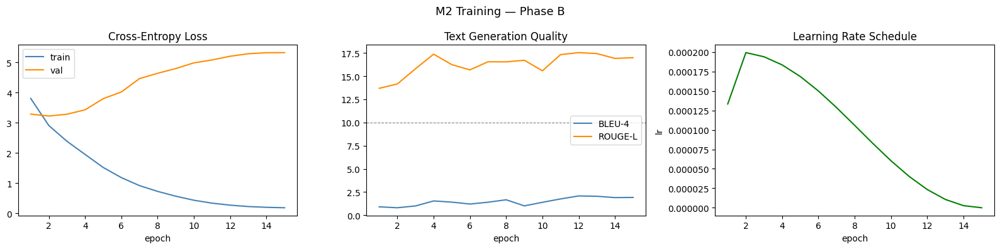

Training summary
  Best BLEU-4   : 2.08  (epoch 12)
  Best ROUGE-L  : 17.54
  Final val loss: 5.3230
  Curve saved   : processed/m2_training_curves.png


In [42]:
# Training curve visualisation

epochs_x = list(range(1, len(history["train_loss"]) + 1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle("M2 Training — Phase B", fontsize=13)

axes[0].plot(epochs_x, history["train_loss"], label="train", color="steelblue")
axes[0].plot(epochs_x, history["val_loss"],   label="val",   color="darkorange")
axes[0].set_title("Cross-Entropy Loss")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(epochs_x, history["bleu4"],   label="BLEU-4",  color="steelblue")
axes[1].plot(epochs_x, history["rouge_l"], label="ROUGE-L", color="darkorange")
axes[1].set_title("Text Generation Quality")
axes[1].set_xlabel("epoch")
axes[1].legend()
axes[1].axhline(10, color="grey", linestyle="--", linewidth=0.8, label="BLEU-4 target")

axes[2].plot(epochs_x, history["lr"], color="green")
axes[2].set_title("Learning Rate Schedule")
axes[2].set_xlabel("epoch")
axes[2].set_ylabel("lr")

plt.tight_layout()
plt.savefig(str(PROCESSED_DIR / "m2_training_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

# Summary table
best_epoch = int(np.argmax(history["bleu4"])) + 1
print("Training summary")
print(f"  Best BLEU-4   : {max(history['bleu4']):.2f}  (epoch {best_epoch})")
print(f"  Best ROUGE-L  : {max(history['rouge_l']):.2f}")
print(f"  Final val loss: {history['val_loss'][-1]:.4f}")
print(f"  Curve saved   : processed/m2_training_curves.png")

# D:  Qualitative Inspection — Generated Queries

In [43]:
# Load best checkpoint for qualitative evaluation

ckpt = torch.load(best_ckpt_path, map_location=DEVICE)

best_model = M2Model(
    prefix_length = ckpt["config"]["prefix_length"],
    freeze_clip   = ckpt["config"]["freeze_clip"],
).to(DEVICE)
best_model.load_state_dict(ckpt["state_dict"])
best_model.eval()

print(f"Loaded checkpoint from epoch {ckpt['epoch']}")
print(f"  BLEU-4  : {ckpt['bleu4']:.2f}")
print(f"  ROUGE-L : {ckpt['rouge_l']:.2f}")
print(f"  val loss: {ckpt['val_loss']:.4f}")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded checkpoint from epoch 12
  BLEU-4  : 2.08
  ROUGE-L : 17.54
  val loss: 5.2030


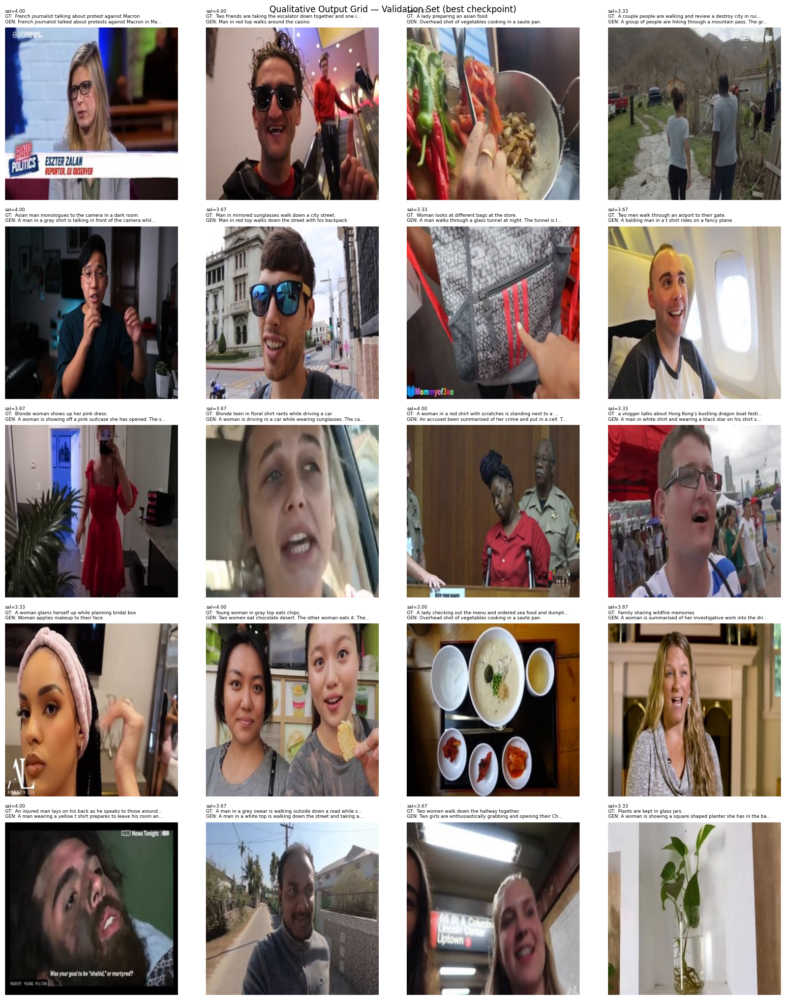

Qualitative grid saved to processed/m2_qualitative_grid.png


In [44]:
# Qualitative output grid — 20 random validation samples
# Each cell shows: frame | generated query | ground-truth query | saliency

N_SHOW      = 20
sample_val  = random.sample(val_pairs, N_SHOW)

# Generate queries for all 20 at once (batched)
batch_px = torch.stack([
    val_transform(Image.open(r["frame_path"]).convert("RGB"))
    for r in sample_val
]).to(DEVICE)

gen_queries = best_model.generate(batch_px, tokenizer, max_new_tokens=MAX_SEQ_LEN)

n_cols = 4
n_rows = math.ceil(N_SHOW / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 4))
fig.suptitle("Qualitative Output Grid — Validation Set (best checkpoint)", fontsize=12)

for i, (pair, gen) in enumerate(zip(sample_val, gen_queries)):
    ax  = axes[i // n_cols][i % n_cols]
    img = Image.open(pair["frame_path"]).convert("RGB")
    ax.imshow(img.resize((224, 224)))
    ax.axis("off")

    gt_short  = pair["query"][:60] + ("..." if len(pair["query"]) > 60 else "")
    gen_short = gen[:60] + ("..." if len(gen) > 60 else "")

    ax.set_title(
        f"sal={pair['mean_saliency']:.2f}\n"
        f"GT:  {gt_short}\n"
        f"GEN: {gen_short}",
        fontsize=6.5, loc="left",
    )

# Hide any unused axes
for j in range(N_SHOW, n_rows * n_cols):
    axes[j // n_cols][j % n_cols].axis("off")

plt.tight_layout()
plt.savefig(str(PROCESSED_DIR / "m2_qualitative_grid.png"), dpi=120, bbox_inches="tight")
plt.show()
print("Qualitative grid saved to processed/m2_qualitative_grid.png")

Per-sample BLEU: 100%|██████████| 160/160 [00:41<00:00,  3.89it/s]

15 worst-scoring validation samples
   qid  saliency    BLEU  GT                                        GENERATED
------------------------------------------------------------------------------------------------------------------------
   153     2.333    0.00  Positive things will happen to you        A woman in a striped shirt is holding 
  1600     3.667    0.00  A lady preparing an asian food            Overhead shot of vegetables cooking in
  1789     3.667    0.00  Asian girl catching some movements of     A student in a white top is sitting in
  2869     4.000    0.00  Two guys recording videos and hanging     The view from Tokyo tower is shown thr
  8716     3.333    0.00  A woman glams herself up while plannin    Woman applies makeup to their face.
  9224     3.667    0.00  Family sharing wildfire memories          A woman is summarised of her investiga
  4515     3.667    1.51  Men sharing some amazing aerial view o    A group of women explore a lush, green
    52     4.000   

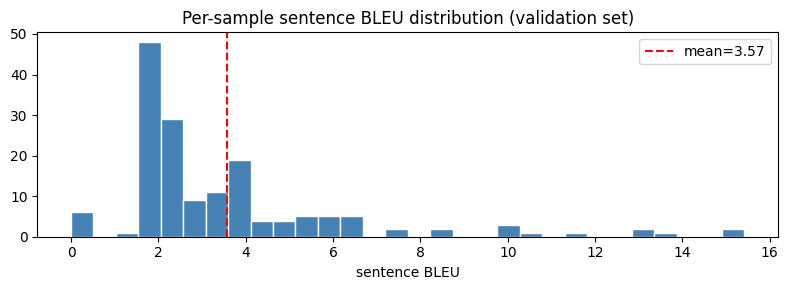


Correlation(saliency, sentence-BLEU) = 0.029
A positive correlation means higher-saliency frames produce better queries.


In [45]:
# Systematic failure analysis
# Compute BLEU-4 per sample, then surface the lowest-scoring 15.
# This shows systematic failure modes (not just bad luck on random samples).

per_sample_scores = []
best_model.eval()

for pair in tqdm(val_pairs, desc="Per-sample BLEU"):
    px  = val_transform(Image.open(pair["frame_path"]).convert("RGB")).unsqueeze(0).to(DEVICE)
    gen = best_model.generate(px, tokenizer, max_new_tokens=MAX_SEQ_LEN)[0]
    # sentence-level BLEU
    bleu_s = sacrebleu.sentence_bleu(gen, [pair["query"]]).score
    per_sample_scores.append({
        "qid"          : pair["qid"],
        "mean_saliency": pair["mean_saliency"],
        "ground_truth" : pair["query"],
        "generated"    : gen,
        "bleu_sentence": bleu_s,
        "frame_path"   : pair["frame_path"],
    })

per_sample_scores.sort(key=lambda x: x["bleu_sentence"])

print("15 worst-scoring validation samples")
print(f"{'qid':>6}  {'saliency':>8}  {'BLEU':>6}  {'GT':40}  GENERATED")
print("-" * 120)
for s in per_sample_scores[:15]:
    gt  = s["ground_truth"][:38]
    gen = s["generated"][:38]
    print(f"{s['qid']:>6}  {s['mean_saliency']:>8.3f}  {s['bleu_sentence']:>6.2f}  {gt:40}  {gen}")

# Distribution of per-sample BLEU scores
bleu_vals = [s["bleu_sentence"] for s in per_sample_scores]
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(bleu_vals, bins=30, color="steelblue", edgecolor="white")
ax.axvline(np.mean(bleu_vals), color="red", linestyle="--",
           label=f"mean={np.mean(bleu_vals):.2f}")
ax.set_title("Per-sample sentence BLEU distribution (validation set)")
ax.set_xlabel("sentence BLEU")
ax.legend()
plt.tight_layout()
plt.show()

# Correlation between saliency and BLEU
sal_vals = [s["mean_saliency"] for s in per_sample_scores]
corr = float(np.corrcoef(sal_vals, bleu_vals)[0, 1])
print(f"\nCorrelation(saliency, sentence-BLEU) = {corr:.3f}")
print("A positive correlation means higher-saliency frames produce better queries.")

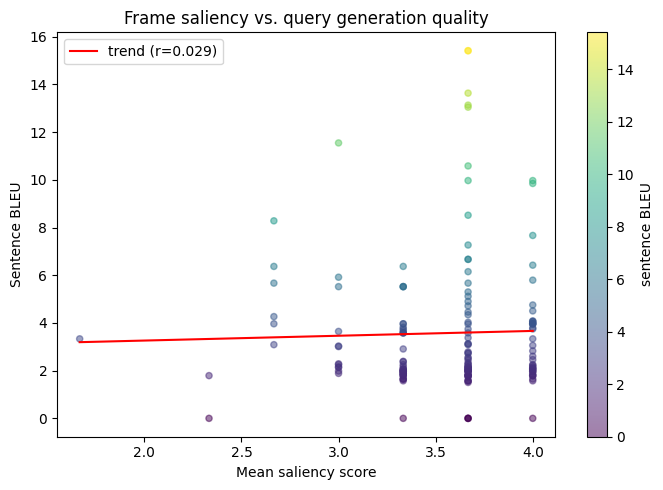

In [46]:
# Saliency vs. BLEU scatter plot
# Useful diagnostic: if high-saliency frames consistently give better BLEU,
# it validates that the saliency-based frame selection in Stage 0 was meaningful.

sal_arr  = np.array([s["mean_saliency"] for s in per_sample_scores])
bleu_arr = np.array([s["bleu_sentence"] for s in per_sample_scores])

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(sal_arr, bleu_arr, alpha=0.5, s=20, c=bleu_arr, cmap="viridis")
plt.colorbar(sc, ax=ax, label="sentence BLEU")

# Linear trend line
m, b = np.polyfit(sal_arr, bleu_arr, 1)
x_line = np.linspace(sal_arr.min(), sal_arr.max(), 100)
ax.plot(x_line, m * x_line + b, color="red", linewidth=1.5,
        label=f"trend (r={corr:.3f})")

ax.set_xlabel("Mean saliency score")
ax.set_ylabel("Sentence BLEU")
ax.set_title("Frame saliency vs. query generation quality")
ax.legend()
plt.tight_layout()
plt.show()

In [47]:
# Final full-validation-set metrics with best checkpoint

val_loss_final, bleu4_final, rouge_l_final = evaluate_metrics(
    best_model, val_loader, tokenizer, n_samples=None  # all 160 samples
)

print("Final validation metrics (best checkpoint, full val set)")
print(f"  Val loss  : {val_loss_final:.4f}")
print(f"  BLEU-4    : {bleu4_final:.2f}")
print(f"  ROUGE-L   : {rouge_l_final:.2f}")

Final validation metrics (best checkpoint, full val set)
  Val loss  : 5.2030
  BLEU-4    : 2.08
  ROUGE-L   : 17.54


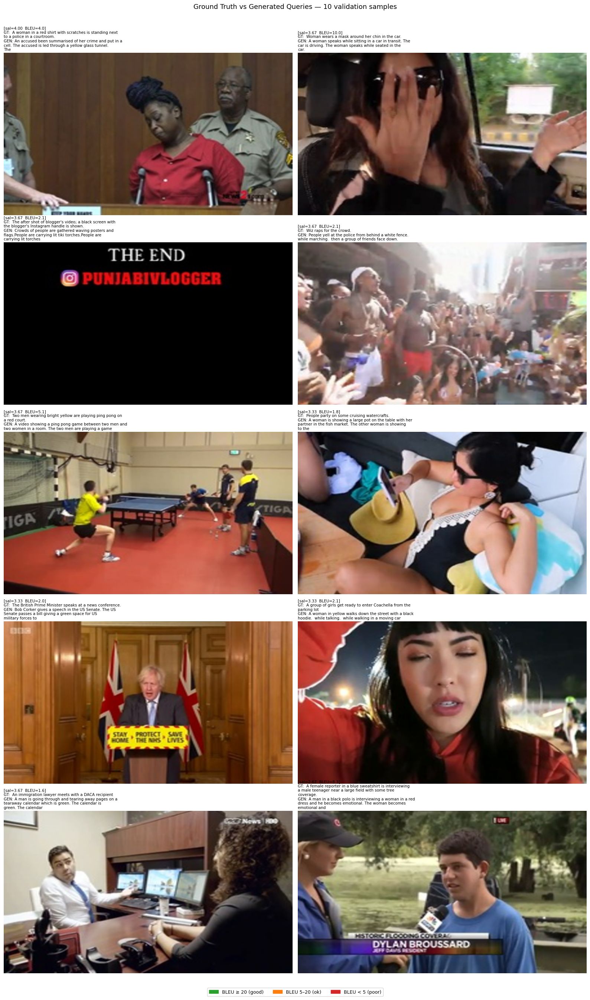


  #   BLEU  Saliency  Ground truth                                   Generated
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  1    4.0     4.000  A woman in a red shirt with scratches is st    An accused been summarised of her crime and
  2   10.0     3.667  Woman wears a mask around her chin in the c    A woman speaks while sitting in a car in tr
  3    2.1     3.667  The after shot of blogger's video; a black     Crowds of people are gathered waving poster
  4    2.1     3.667  Wiz raps for the crowd.                        People yell at the police from behind a whi
  5    5.1     3.667  Two men wearing bright yellow are playing p    A video showing a ping pong game between tw
  6    1.8     3.333  People party on some cruising watercrafts.     A woman is showing a large pot on the table
  7    2.0     3.333  The British Prime Minister speaks at a news    Bob Corker gives a speech in the US Senate

In [49]:
N_SHOW = 10
sample_val = random.sample(val_pairs, N_SHOW)

# Batch-generate for all 10 at once
batch_px = torch.stack([
    val_transform(Image.open(r["frame_path"]).convert("RGB"))
    for r in sample_val
]).to(DEVICE)

gen_queries = best_model.generate(batch_px, tokenizer, max_new_tokens=MAX_SEQ_LEN)

# Layout: 2 columns × 5 rows, each cell = image + text block beneath
n_cols, n_rows = 2, 5
fig = plt.figure(figsize=(16, n_rows * 5.2))
fig.suptitle("Ground Truth vs Generated Queries — 10 validation samples",
             fontsize=13, y=1.01)

for i, (pair, gen) in enumerate(zip(sample_val, gen_queries)):
    ax = fig.add_subplot(n_rows, n_cols, i + 1)
    img = Image.open(pair["frame_path"]).convert("RGB")
    ax.imshow(img.resize((336, 189)))           # 16:9 thumbnail ratio
    ax.axis("off")

    gt_wrapped  = "\n".join(textwrap.wrap(pair["query"], width=55))
    gen_wrapped = "\n".join(textwrap.wrap(gen,           width=55))

    # Sentence-level BLEU for this pair
    bleu_s = sacrebleu.sentence_bleu(gen, [pair["query"]]).score

    title_text = (
        f"[sal={pair['mean_saliency']:.2f}  BLEU={bleu_s:.1f}]\n"
        f"GT:  {gt_wrapped}\n"
        f"GEN: {gen_wrapped}"
    )
    ax.set_title(title_text, fontsize=7.5, loc="left",
                 color="black", pad=4,
                 multialignment="left")

    # Colour-code border: green = good (BLEU ≥ 20), orange = ok, red = poor
    border_color = "#2ca02c" if bleu_s >= 20 else ("#ff7f0e" if bleu_s >= 5 else "#d62728")
    for spine in ax.spines.values():
        spine.set_edgecolor(border_color)
        spine.set_linewidth(2.5)

legend_patches = [
    mpatches.Patch(color="#2ca02c", label="BLEU ≥ 20 (good)"),
    mpatches.Patch(color="#ff7f0e", label="BLEU 5–20 (ok)"),
    mpatches.Patch(color="#d62728", label="BLEU < 5 (poor)"),
]
fig.legend(handles=legend_patches, loc="lower center", ncol=3,
           fontsize=9, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
plt.show()

# Print comparison table
print(f"\n{'#':>3}  {'BLEU':>5}  {'Saliency':>8}  {'Ground truth':45}  Generated")
print("─" * 130)
for i, (pair, gen) in enumerate(zip(sample_val, gen_queries)):
    bleu_s = sacrebleu.sentence_bleu(gen, [pair["query"]]).score
    gt_trunc  = pair["query"][:43]
    gen_trunc = gen[:43]
    print(f"{i+1:>3}  {bleu_s:>5.1f}  {pair['mean_saliency']:>8.3f}  {gt_trunc:45}  {gen_trunc}")

In [51]:
import io, ipywidgets as widgets
from IPython.display import display, clear_output
from PIL import Image
import torch

# Widget layout
uploader    = widgets.FileUpload(accept="image/*", multiple=False,
                                 description="Upload image")
beam_slider = widgets.IntSlider(value=1, min=1, max=5, step=1,
                                description="Beam size",
                                continuous_update=False,
                                style={"description_width": "80px"})
gen_button  = widgets.Button(description="Generate query",
                             button_style="primary", icon="search")
out         = widgets.Output()

ui = widgets.VBox([
    widgets.HTML("<b>M2 — Thumbnail → Query Generator</b><br>"
                 "<span style='color:gray;font-size:12px'>"
                 "Upload a video thumbnail (or any image) to generate a search query.</span>"),
    widgets.HBox([uploader, beam_slider, gen_button]),
    out,
])
display(ui)

# Inference callback
def on_generate(_):
    with out:
        clear_output(wait=True)

        if not uploader.value:
            print("⚠  Please upload an image first.")
            return

        # Decode uploaded bytes → PIL image
        uploaded_item = list(uploader.value.values())[0]
        img_bytes = uploaded_item["content"]          # memoryview or bytes
        img = Image.open(io.BytesIO(bytes(img_bytes))).convert("RGB")

        # Pre-process
        px = val_transform(img).unsqueeze(0).to(DEVICE)

        # Generate
        best_model.eval()
        with torch.no_grad():
            queries = best_model.generate(
                px, tokenizer,
                max_new_tokens=MAX_SEQ_LEN,
                beam_size=beam_slider.value,
            )
        generated = queries[0]

        fig, axes = plt.subplots(1, 2, figsize=(13, 4),
                                 gridspec_kw={"width_ratios": [1, 1.6]})

        axes[0].imshow(img.resize((336, 189)))
        axes[0].axis("off")
        axes[0].set_title("Input image", fontsize=10)

        # Text panel
        axes[1].axis("off")
        axes[1].set_facecolor("#f8f8f8")

        result_text = (
            f"Generated query\n"
            f"{'─' * 42}\n\n"
            f"{generated}\n\n\n"
            f"Settings\n"
            f"{'─' * 42}\n"
            f"Beam size  : {beam_slider.value}\n"
            f"Max tokens : {MAX_SEQ_LEN}\n"
            f"Model      : CLIP ViT-B/32 + GPT-2"
        )
        axes[1].text(0.04, 0.96, result_text,
                     transform=axes[1].transAxes,
                     fontsize=10, verticalalignment="top",
                     fontfamily="monospace",
                     bbox=dict(boxstyle="round,pad=0.5",
                               facecolor="white", edgecolor="#cccccc"))

        plt.tight_layout()
        plt.show()

        print(f"\n→  Query: {generated}")

gen_button.on_click(on_generate)